# Measured oscillator networks

How does dependence character reorganise along a controlled coupling sweep? Start with [hybrid ER](https://zenodo.org/records/17451096); [small-world](https://zenodo.org/records/17451530) is the transfer candidate. All 28 channels and the full 10 s recording are retained during the sampling audit. One sweep per topology; settings are not independent experimental replicates.

In [1]:
from pathlib import Path
import json, sys, os
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/spi_spi_contract.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from scripts.plot_hardware_pilot import sampling_figures, result_figures
REMOTE = Path('/g/data/ql44/we2614/mts-spi-study/representation/empirical/hardware-pilot-261012')
RUN = Path(os.environ.get('HARDWARE_ROOT', str(REMOTE if REMOTE.exists() else ROOT/'results/hardware-pilot-261012')))
SCOPE = RUN/'scope-er-transition'
MODEL_NAME = 'pilot'
def show(folder, names):
    for name in names:
        display(Image(filename=str(folder/f'{name}.png')))
print(f'Results: {RUN}')

Results: /Users/wedi0306/Code/mts-spi-study-cluster/results/hardware-pilot-261012


## Sampling

All **29 recordings support T=5,000 (500 Hz, full 10 s)**; T=2,000 loses the ~116 Hz carrier. Maximum waveform NRMSE is 0.026 and PLV edge RMSE 0.00023. Across settings 23→24, mean phase concentration changes 0.840→0.866 while its smoothed temporal SD falls 0.063→0.0068: a candidate contrast beyond mean alignment. R denotes Hilbert phase concentration; R_s uses five-cycle smoothing. Threshold-crossing counts vary slightly with sampling and do not establish physical states.

Smallest candidate passing numerical checks: 5000


,fs,reconstruction_nrmse_p95,plv_rmse,envelope_rmse,synchrony_trace_rmse,high_fraction_error,passes
T,,,,,,,
2000,200.0,0.999471,0.333834,0.958120,0.949115,1.000000,False
5000,500.0,0.025530,0.000230,0.027342,0.001169,0.002756,True
10000,1000.0,0.015370,0.000115,0.001823,0.000052,0.001950,True


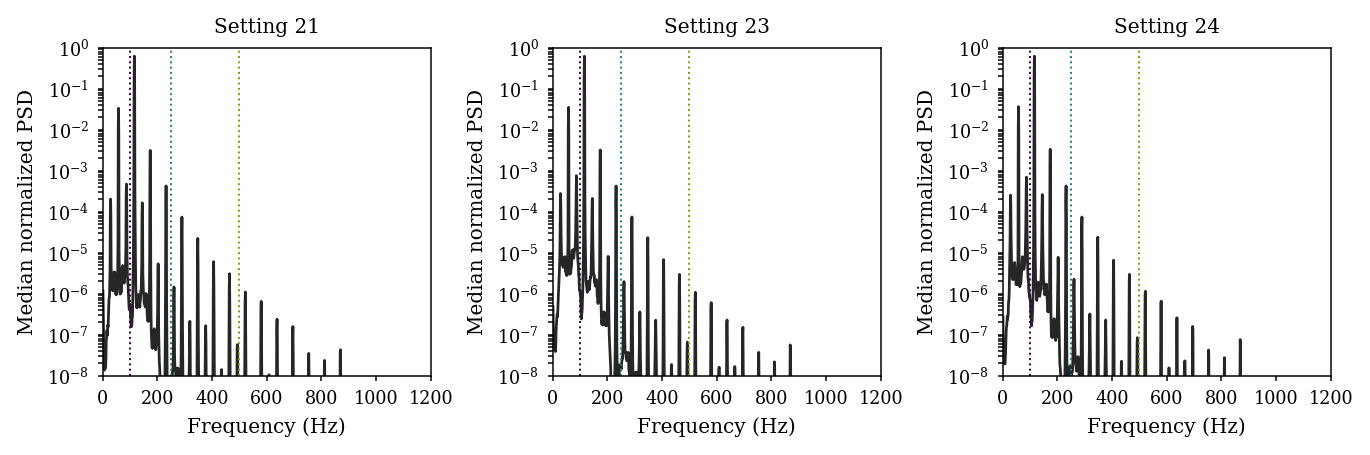

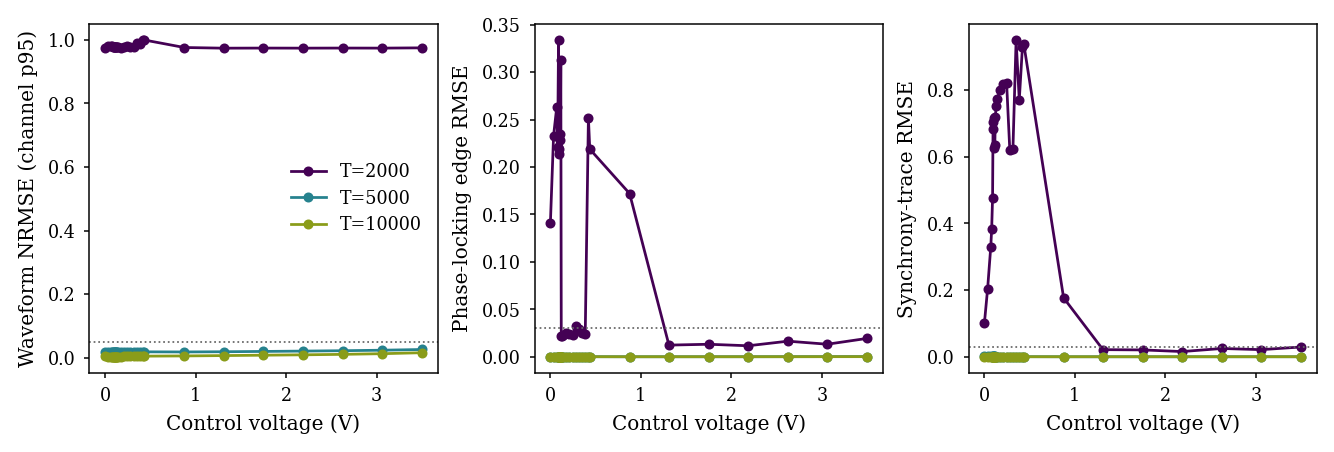

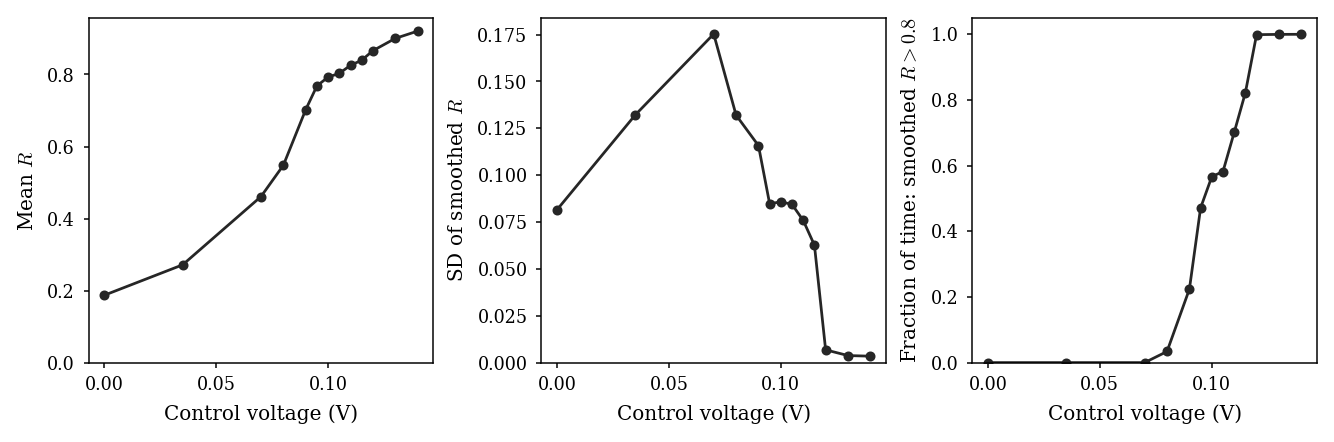

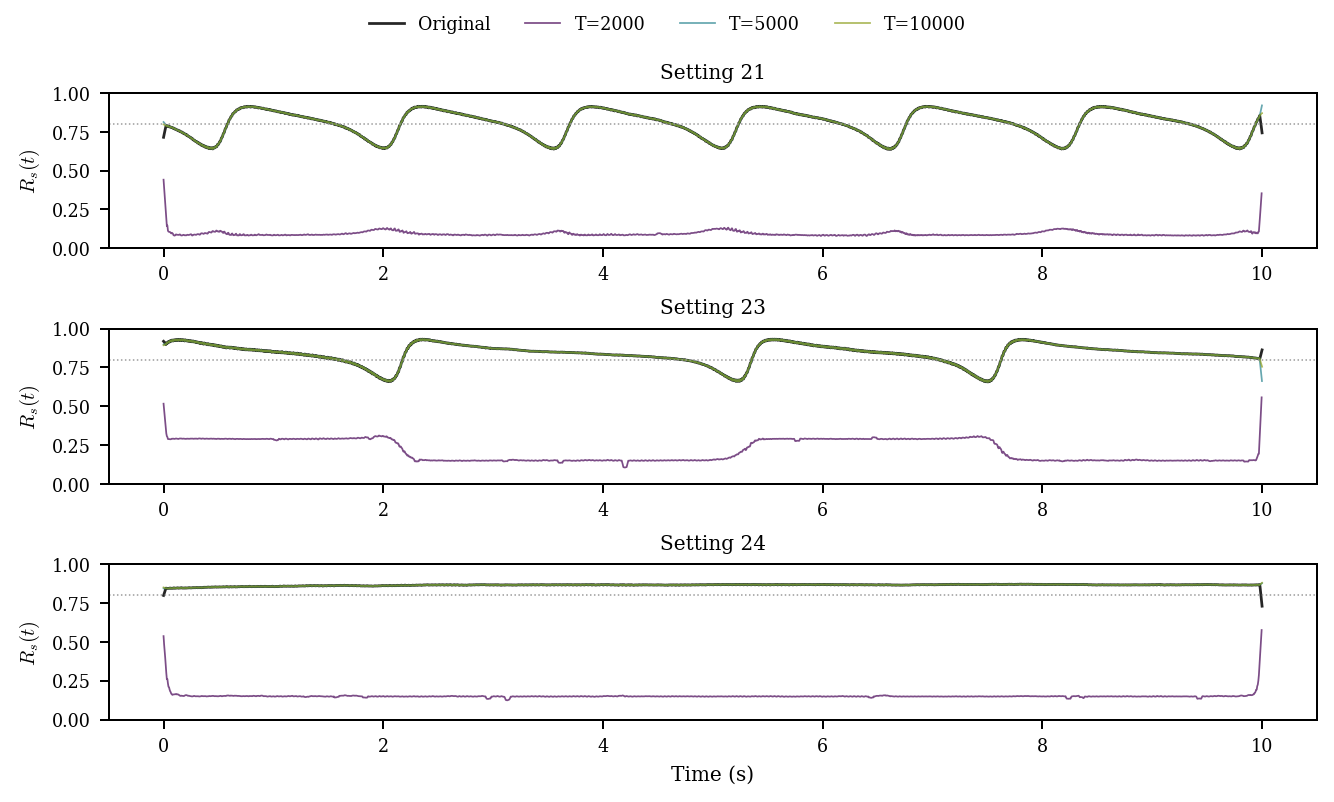

In [2]:
if (SCOPE/'sampling-decision.json').exists():
    decision = json.loads((SCOPE/'sampling-decision.json').read_text())
    print('Smallest candidate passing numerical checks:', decision['selected_T'])
    audit = pd.read_csv(SCOPE/'sampling-audit.csv')
    display(audit.groupby('T')[['fs','reconstruction_nrmse_p95','plv_rmse','envelope_rmse','synchrony_trace_rmse','high_fraction_error','passes']].agg({'fs':'first','reconstruction_nrmse_p95':'max','plv_rmse':'max','envelope_rmse':'max','synchrony_trace_rmse':'max','high_fraction_error':'max','passes':'all'}))
    figures = sampling_figures(SCOPE, trace_steps=[21, 23, 24], focus_max_step=28)
    show(figures, ['spectra','sampling-fidelity','coordination-profile','synchrony-traces'])
else:
    print('Waveform acquisition pending; T has not been selected.')

## Dependence geometry

Centred SPI–SPI PCA, fitted on alternating development settings without coupling labels. Held settings assess interpolation within the same sweep. PC signs follow the largest coefficient; trajectories are exploratory, not a claimed phase transition.

In [3]:
candidate = RUN/MODEL_NAME/'analysis'
ANALYSIS = candidate if (candidate/'summary.json').exists() else None
if ANALYSIS:
    report = json.loads((ANALYSIS/'summary.json').read_text())
    print(ANALYSIS.parent.name)
    display(pd.Series({k:report[k] for k in ['retained_features','max_imputed_fraction','top20_double_correlation']}))
    print('PC1 leave-setting loading cosine range:', np.min(report['leave_setting_loading_cosines']), np.max(report['leave_setting_loading_cosines']))
    figures = result_figures(ANALYSIS, SCOPE)
    show(figures, ['geometry'])
else:
    print('Full-p90 smoke exceeded 48 GiB. The PSI memory repair passed hardware validation; the checkpointed full-p90 retry is submitted. No empirical SPI–SPI interpretation yet.')

Full-p90 smoke exceeded 48 GiB. The PSI memory repair passed hardware validation; the checkpointed full-p90 retry is submitted. No empirical SPI–SPI interpretation yet.


## Features and channel-pair explanations

Global PC1 ranks are preserved. The second gallery omits pairs with two classical-correlation endpoints without refitting PCA. Large coefficients are not unique mechanistic contributions; interpretation requires the original edge profiles and sampling checks.

In [4]:
if ANALYSIS:
    show(figures, ['features-top','features-filtered','edge-profiles'])
    rankings = pd.read_csv(ANALYSIS/'feature-rankings.csv')
    display(rankings.loc[~rankings.both_correlation, ['rank','spi_a','spi_b','weight']].head(9))